[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/MFM/blob/main/notebooks/RO/capitol12_notebook_seminar.ipynb)

# Modelarea piețelor financiare — Seminarul 12: Opțiuni și suprafața de volatilitate

*Notebook de seminar. Daniel Traian Pele, Antoaneta Amza, Academia de Studii Economice din București.*

- Problemele **[Rezolvat]** conțin rezolvarea completă; problemele **[Propus]** le rezolvați dumneavoastră.
- Partea A: derivări verificate pe cifre (A1–A8); Partea B: estimare și inferență (B1–B8); Partea C: întrebări deschise și evaluarea critică a unui răspuns generat de inteligență artificială (Artificial Intelligence, AI).

P&L înseamnă profit and loss (profit sau pierdere); OTM înseamnă out of the money.

Ordinea exercițiilor urmează traseul PDF-ului. C1 cere evaluarea unui răspuns AI; C2 și C3 sînt extensii de cercetare. Unele grafice explicate au link la pagina PDF corespunzătoare; figurile generate aici acoperă B1 și B4.

> Rezolvările se discută la seminar.

> **Lucrați în Google Colab? Salvați mai întîi propria copie.** Folosiți File → Save a copy in Drive pentru a păstra codul și rezultatele. Celula opțională de mai jos poate salva și graficele/tabelele în Drive; montați Drive numai dacă activați SAVE_TO_DRIVE.

In [1]:
# Opțional (doar Colab): păstrați fișierele create în Google Drive
SAVE_TO_DRIVE = False   # set to True, run this cell and allow access to your Drive

import os
OUT_DIR = '.'
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/MFM/Chapter_12'
    os.makedirs(OUT_DIR, exist_ok=True)
    os.chdir(OUT_DIR)  # relative chart and CSV outputs persist in Drive
print('Save your outputs to:', os.path.abspath(OUT_DIR))


Save your outputs to: /Users/danpele/Documents/2026 MFM/MFM/notebooks/RO


In [2]:
import os
import json
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import stats, optimize, integrate
import statsmodels.api as sm
import warnings
warnings.filterwarnings('ignore')

N, n = stats.norm.cdf, stats.norm.pdf

## Stil și funcții ajutătoare

In [3]:
# Chart style: transparent background, legend below the plot
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['axes.facecolor'] = 'none'
plt.rcParams['savefig.facecolor'] = 'none'
plt.rcParams['savefig.transparent'] = True
plt.rcParams['axes.grid'] = False
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 9
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.linewidth'] = 0.6
plt.rcParams['lines.linewidth'] = 1.1
plt.rcParams['legend.facecolor'] = 'none'
plt.rcParams['legend.framealpha'] = 0
plt.rcParams['legend.fontsize'] = 8

# Course colours
MainBlue = '#1A3A6E'
IDAred   = '#CD0000'
Forest   = '#2E7D32'
Amber    = '#B5853F'
Orange   = '#E67E22'
Purple   = '#8E44AD'
Crimson  = '#DC3545'
Navy     = '#1F2A44'   # reference lines (no grey in charts)
BandBlue = '#C5D2E8'   # light MainBlue tint for confidence / reference bands
Gray, LightGray = Navy, BandBlue   # legacy names kept for importing scripts
Teal     = '#17A2B8'

HERE = '.'
SEED = 42
BASE = {'S': 100.0, 'K': 100.0, 'T': 0.25, 'r': 0.04, 'sigma': 0.2}
HEDGE = {'S0': 100.0, 'K': 100.0, 'T': 0.25, 'r': 0.04, 'sigma': 0.2, 'mu': 0.08, 'nstep': 252, 'npath': 20000}


def save_fig(name):
    """Save the figure as PDF and transparent PNG in the current folder."""
    plt.savefig(f'{name}.pdf', bbox_inches='tight', transparent=True)
    plt.savefig(f'{name}.png', bbox_inches='tight', transparent=True, dpi=180)
    plt.show()
    plt.close()
    print(f"   saved {name}")


def legend_outside_bottom(ax, ncol=2, y=-0.22):
    """Place the legend outside the plot, bottom centre."""
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)


def fig_legend_bottom(fig, handles, ncol=3, y=0.0):
    """One legend for a multi-panel figure, below the figure."""
    fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)


def nw_mean(x, lags):
    """Mean and Newey-West (HAC) standard error of a series."""
    x = np.asarray(x, float)
    m = sm.OLS(x, np.ones_like(x)).fit(cov_type='HAC', cov_kwds={'maxlags': lags})
    return float(m.params[0]), float(m.bse[0])


def jsonable(o):
    if isinstance(o, dict):
        return {str(k): jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple, np.ndarray)):
        return [jsonable(v) for v in o]
    if isinstance(o, (np.floating, np.integer)):
        return o.item()
    if isinstance(o, pd.Timestamp):
        return str(o)
    return o


import tempfile
# SAVE_TO_DRIVE = True (celula Colab de mai sus): graficele și tabelele merg în OUT_DIR, în Google Drive; altfel, într-un folder temporar
KEEP = bool(globals().get('SAVE_TO_DRIVE', False))
HERE = globals().get('OUT_DIR', '.') if KEEP else tempfile.gettempdir()


def save_fig(name):
    """Afiseaza figura; cu SAVE_TO_DRIVE, o salveaza si ca PNG in OUT_DIR."""
    if KEEP:
        plt.savefig(os.path.join(HERE, f'{name}.png'), bbox_inches='tight', transparent=True, dpi=180)
    plt.show()
    plt.close()

## Date

- Prețuri zilnice close pînă la 18 septembrie 2026: S&P 500, Bitcoin și Cboe Volatility Index (VIX); VIX3M este varianta la trei luni folosită în extensia despre semnal.
- Lanțul de opțiuni Bitcoin: snapshot Deribit din 22 septembrie 2026; Deribit Volatility Index (DVOL), cu orizont de 30 de zile pentru volatilitatea implicită.
- Volatilitatea implicită este exprimată în procente anualizate. Folosiți convențiile de dată din fiecare exercițiu; zilele de tranzacționare diferă de cele calendaristice.

In [4]:
REPO_RAW = 'https://raw.githubusercontent.com/danpele/MFM/main/data/market/'
# course data: local copy when the notebook runs inside the repository, otherwise read online
MARKET_DIR = next((os.path.join(d, 'data', 'market') for d in ('.', '..', '../..', '../../..')
                   if os.path.isdir(os.path.join(d, 'data', 'market'))), '')
SNAP_DIR = next((d for d in ('.', '../Quantlets/Ch_12', '../../Quantlets/Ch_12')
                 if os.path.exists(os.path.join(d, 'ch12_deribit_snapshot.csv'))), '.')
END = '2026-09-18'

# name -> (symbol, field, type)
SERIES = {
    'sp500': ('GSPC.INDX', 'close', 'index'),
    'spy':   ('SPY.US', 'adjusted_close', 'etf'),
    'btc':   ('BTC-USD.CC', 'close', 'crypto'),
    'vix':   ('VIX.INDX', 'close', 'vol'),
    'vix9d': ('VIX9D.INDX', 'close', 'vol'),
    'vix3m': ('VIX3M.INDX', 'close', 'vol'),
    'vvix':  ('VVIX.INDX', 'close', 'vol'),
}
DERIBIT = 'https://www.deribit.com/api/v2/public/'
SNAP_RAW = 'https://raw.githubusercontent.com/danpele/MFM/main/Quantlets/Ch_12/ch12_deribit_snapshot.csv'


def read_market(symbol):
    """Read the daily series of one symbol from the course data (local copy or online)."""
    fname = f'{symbol}.csv'
    path = os.path.join(MARKET_DIR, fname)
    src = path if os.path.exists(path) else REPO_RAW + fname
    return pd.read_csv(src, index_col='date', parse_dates=True).sort_index()


def load_close(name, start=None, end=END):
    """Daily price (or index level); except for crypto assets, weekdays only
    (days with an unchanged close are kept: they are real trading days)."""
    symbol, col, kind = SERIES[name]
    s = read_market(symbol)[col].loc[start:end]
    s = s[s > 0].dropna()
    if kind != 'crypto':
        s = s[s.index.dayofweek < 5]
    return s.rename(name)


def log_returns(name, start=None, end=END):
    """Log returns on the series' own calendar."""
    return np.log(load_close(name, start, end)).diff().dropna().rename(name)


def spy_open_close(start=None, end=END):
    """Daily SPY open and close (unadjusted prices: the same-day ratio does not depend on adjustments)."""
    d = read_market('SPY.US').loc[start:end, ['open', 'close']]
    d = d[(d > 0).all(axis=1)]
    return d[d.index.dayofweek < 5]


def _get(method, **params):
    url = DERIBIT + method + '?' + '&'.join(f'{k}={v}' for k, v in params.items())
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    return json.load(urllib.request.urlopen(req, timeout=60))['result']


def deribit_chain(path=None, refresh=False):
    """BTC option chain (mark prices, implied volatilities) at the snapshot time."""
    path = path or os.path.join(SNAP_DIR, 'ch12_deribit_snapshot.csv')
    if not refresh:
        for src in (path, SNAP_RAW):
            try:
                return pd.read_csv(src, parse_dates=['snapshot_utc', 'expiry'])
            except Exception:
                pass
    rows = _get('get_book_summary_by_currency', currency='BTC', kind='option')
    t0 = pd.Timestamp.now(tz='UTC').floor('min').tz_localize(None)
    out = []
    for x in rows:
        _, exp, strike, cp = x['instrument_name'].split('-')
        out.append(dict(snapshot_utc=t0, instrument=x['instrument_name'],
                        expiry=pd.to_datetime(exp, format='%d%b%y') + pd.Timedelta(hours=8),
                        strike=float(strike), type='call' if cp == 'C' else 'put',
                        mark_iv=x['mark_iv'], mark_price=x['mark_price'], bid=x['bid_price'], ask=x['ask_price'],
                        forward=x['underlying_price'], index=x['estimated_delivery_price'],
                        open_interest=x['open_interest'], volume_usd=x['volume_usd']))
    d = pd.DataFrame(out).sort_values(['expiry', 'strike', 'type']).reset_index(drop=True)
    d.to_csv(path, index=False)
    return d


def dvol_history(start='2021-03-24', end=END):
    """DVOL index (30-day implied volatility of BTC options, annualised, in %), daily values."""
    t1 = int(pd.Timestamp(end).tz_localize('UTC').timestamp() * 1000) + 86_400_000
    t0 = int(pd.Timestamp(start).tz_localize('UTC').timestamp() * 1000)
    data = []
    while True:
        r = _get('get_volatility_index_data', currency='BTC', start_timestamp=t0, end_timestamp=t1, resolution='1D')
        data += r['data']
        if not r.get('continuation') or r['continuation'] <= t0:
            break
        t1 = r['continuation']
    d = pd.DataFrame(data, columns=['t', 'open', 'high', 'low', 'close']).drop_duplicates('t')
    d.index = pd.to_datetime(d['t'], unit='ms').dt.normalize()
    return d.sort_index()['close'].loc[start:end].rename('dvol')

[Verificați snapshotul de date](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#page=5): Snapshotul publicat are 9.245 de zile comune, 1990-01-02–2026-09-18, 986 de contracte și 11 scadențe. Primele/ultimele prețuri de închidere: S&P 500: 359,69/7650,50; VIX: 17,24/14,81. O diferență indică altă versiune a datelor sau altă aliniere; clarificați-o înainte de a compara estimările.

In [5]:
_check_px = pd.concat([load_close('sp500'), load_close('vix')], axis=1, join='inner').dropna()
_check_chain = deribit_chain()
print('Common days:', len(_check_px), 'range:', _check_px.index[0].date(), _check_px.index[-1].date())
print('First/last closes:', _check_px.iloc[[0, -1]].to_dict())
print('Option contracts:', len(_check_chain), 'expiries:', _check_chain['expiry'].nunique())

Common days: 9245 range: 1990-01-02 2026-09-18
First/last closes: {'sp500': {Timestamp('1990-01-02 00:00:00'): 359.69, Timestamp('2026-09-18 00:00:00'): 7650.5}, 'vix': {Timestamp('1990-01-02 00:00:00'): 17.24, Timestamp('2026-09-18 00:00:00'): 14.81}}
Option contracts: 986 expiries: 11


## Instrumente de evaluare a opțiunilor

- `bs_price`, `bs_greeks`: Black–Scholes și senzitivitățile; `implied_vol`, `newton_iv`: volatilitatea implicită.
- `merton_price`, `heston_price`: modele cu salturi și cu volatilitate stochastică.
- `svi_w`, `svi_fit`: zîmbetul Stochastic Volatility Inspired (SVI); `delta_hedge`: delta hedging discret.

BS abreviază Black–Scholes, GBM înseamnă Geometric Brownian Motion (mișcare browniană geometrică), iar RND înseamnă Risk-Neutral Density (densitate sub măsura neutră la risc).

In [6]:
def bs_price(S, K, T, r, sigma, kind='call', q=0.0):
    """Black-Scholes price of a European option."""
    S, K, T, sigma = map(np.asarray, (S, K, T, sigma))
    d1 = (np.log(S / K) + (r - q + 0.5 * sigma ** 2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    if kind == 'call':
        return S * np.exp(-q * T) * N(d1) - K * np.exp(-r * T) * N(d2)
    return K * np.exp(-r * T) * N(-d2) - S * np.exp(-q * T) * N(-d1)


def bs_greeks(S, K, T, r, sigma, kind='call', q=0.0):
    """Delta, gamma, vega (per volatility point), theta (per calendar day), rho; plus d1, d2."""
    S, K, T, sigma = map(np.asarray, (S, K, T, sigma))
    d1 = (np.log(S / K) + (r - q + 0.5 * sigma ** 2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    gamma = np.exp(-q * T) * n(d1) / (S * sigma * np.sqrt(T))
    vega = S * np.exp(-q * T) * n(d1) * np.sqrt(T) / 100
    common = -S * np.exp(-q * T) * n(d1) * sigma / (2 * np.sqrt(T))
    if kind == 'call':
        delta = np.exp(-q * T) * N(d1)
        theta = common - r * K * np.exp(-r * T) * N(d2) + q * S * np.exp(-q * T) * N(d1)
        rho = K * T * np.exp(-r * T) * N(d2) / 100
    else:
        delta = -np.exp(-q * T) * N(-d1)
        theta = common + r * K * np.exp(-r * T) * N(-d2) - q * S * np.exp(-q * T) * N(-d1)
        rho = -K * T * np.exp(-r * T) * N(-d2) / 100
    return dict(d1=d1, d2=d2, delta=delta, gamma=gamma, vega=vega, theta=theta / 365, rho=rho)


def implied_vol(price, S, K, T, r, kind='call', q=0.0, lo=1e-4, hi=5.0):
    """Implied volatility: the unique solution of BS(sigma) = price (vega > 0)."""
    f = lambda s: bs_price(S, K, T, r, s, kind, q) - price
    if f(lo) > 0 or f(hi) < 0:
        return np.nan
    return optimize.brentq(f, lo, hi, xtol=1e-10)


def newton_iv(price, S, K, T, r, sigma0=0.2, kind='call', steps=4):
    """Newton steps: sigma_{k+1} = sigma_k - (BS(sigma_k) - price) / vega(sigma_k)."""
    out, s = [], sigma0
    for _ in range(steps):
        p = float(bs_price(S, K, T, r, s, kind))
        v = float(bs_greeks(S, K, T, r, s, kind)['vega']) * 100
        s_new = s - (p - price) / v
        out.append(dict(sigma=s, price=p, vega=v, sigma_next=s_new))
        s = s_new
    return out


def merton_price(S, K, T, r, sigma, lam, mu_j, sig_j, kind='call', nmax=60):
    """Merton (1976): log-normal jumps ln(1+J) ~ N(mu_j, sig_j^2), intensity lam; Poisson series of BS prices."""
    kappa = np.exp(mu_j + 0.5 * sig_j ** 2) - 1
    lam2 = lam * (1 + kappa)
    tot = 0.0
    for k in range(nmax):
        s_k = np.sqrt(sigma ** 2 + k * sig_j ** 2 / T)
        r_k = r - lam * kappa + k * np.log(1 + kappa) / T
        w = stats.poisson.pmf(k, lam2 * T)
        tot = tot + w * bs_price(S, K, T, r_k, s_k, kind)
    return tot


def heston_price(S, K, T, r, v0, kappa, theta, xi, rho, kind='call'):
    """Heston (1993): call price by the Lewis (2001) formula, with the characteristic function of ln(S_T/F) (stable form)."""
    def phi(u):
        d = np.sqrt((rho * xi * 1j * u - kappa) ** 2 + xi ** 2 * (1j * u + u ** 2))
        g = (kappa - rho * xi * 1j * u - d) / (kappa - rho * xi * 1j * u + d)
        e = np.exp(-d * T)
        C = kappa * theta / xi ** 2 * ((kappa - rho * xi * 1j * u - d) * T - 2 * np.log((1 - g * e) / (1 - g)))
        D = (kappa - rho * xi * 1j * u - d) / xi ** 2 * (1 - e) / (1 - g * e)
        return np.exp(C + D * v0)
    x = np.log(S / K) + r * T
    f = lambda u: (np.exp(1j * u * x) * phi(u - 0.5j)).real / (u ** 2 + 0.25)
    # integral over [0, 2^14] in dyadic pieces: a cut at u = 200 leaves an error of about 1e-5 in the price, which
    # visibly moves deep out-of-the-money implied volatilities
    edges = np.r_[0.0, 2.0 ** np.arange(15)]
    integral = sum(integrate.quad(f, a, b, limit=200, epsabs=1e-14, epsrel=1e-12)[0] for a, b in zip(edges[:-1], edges[1:]))
    call = S - np.sqrt(S * K) * np.exp(-r * T / 2) / np.pi * integral
    return call if kind == 'call' else call - S + K * np.exp(-r * T)


def svi_w(k, a, b, rho, m, s):
    """SVI (Gatheral): total implied variance w(k) = a + b (rho (k - m) + sqrt((k - m)^2 + s^2)), k = ln(K/F)."""
    return a + b * (rho * (k - m) + np.sqrt((k - m) ** 2 + s ** 2))


def svi_fit(k, w, weights=None, *, return_diagnostics=False):
    """Fit the original weighted total-variance SSE within the original SVI box.

    Six starts and an analytic Jacobian resolve the local numerical fit. Boundary
    solutions remain box-dependent; convergence is not proof of a global optimum.
    Optional diagnostics expose all attempts without changing the default result.
    """
    import hashlib
    import scipy
    svi_fit.last_diagnostics = None
    k, w = np.asarray(k, dtype=float), np.asarray(w, dtype=float)
    wt = np.ones_like(w) if weights is None else np.asarray(weights, dtype=float)
    if (k.ndim != 1 or k.size == 0 or w.shape != k.shape or wt.shape != k.shape
            or not np.all(np.isfinite(k)) or not np.all(np.isfinite(w))
            or not np.all(np.isfinite(wt)) or np.any(wt < 0) or not np.isfinite(wt.sum()) or wt.sum() <= 0):
        raise ValueError('SVI requires finite equal-length vectors and nonnegative weights with positive sum.')
    bounds = np.array([(-1, 5), (1e-6, 10), (-0.999, 0.999), (-2, 2), (1e-4, 3)]).T
    root_wt = np.sqrt(wt)
    def residual(p):
        return root_wt * (svi_w(k, *p) - w)
    def jacobian(p):
        a, b, rho, m, s = p
        u = k - m
        d = np.sqrt(u * u + s * s)
        return root_wt[:, None] * np.column_stack((np.ones_like(k), rho*u+d,
                    b*u, b*(-rho-u/d), b*s/d))
    def fingerprint(values):
        return hashlib.sha256(np.ascontiguousarray(values, dtype='<f8').tobytes()).hexdigest()
    diagnostics = dict(input_sha256={name: fingerprint(value) for name, value in
                       [('k', k), ('w', w), ('weights', wt)]},
                       numpy=np.__version__, scipy=scipy.__version__, bounds=bounds.tolist(),
                       method='trf', loss='linear', x_scale='jac', ftol=None,
                       xtol=1e-14, gtol=1e-14, max_nfev=20000, attempts=[])
    svi_fit.last_diagnostics = diagnostics
    candidates = []
    for rho0 in (-0.5, 0.0, 0.3):
        for s0 in (0.05, 0.2):
            x0 = [max(w.min() * 0.5, 1e-4), 0.1, rho0, 0.0, s0]
            row = dict(start=len(diagnostics['attempts']), x0=list(x0), valid=False)
            try:
                res = optimize.least_squares(residual, x0, jac=jacobian, bounds=bounds,
                    method='trf', loss='linear', x_scale='jac', ftol=None,
                    xtol=1e-14, gtol=1e-14, max_nfev=20000)
                p = np.asarray(res.x)
                r, J = residual(p), jacobian(p)
                sse = float(r @ r)
                grad = 2 * J.T @ r
                pg = grad.copy()
                pg[(p <= bounds[0] + 1e-10) & (grad > 0)] = 0
                pg[(p >= bounds[1] - 1e-10) & (grad < 0)] = 0
                denom = 2 * np.linalg.norm(J, 2) * np.linalg.norm(r)
                scaled_pg = float(np.max(np.abs(pg)) / max(denom, np.finfo(float).tiny))
                if np.linalg.norm(r) == 0:
                    scaled_pg = 0.0
                valid = bool(res.success and res.status > 0 and np.all(np.isfinite(p))
                    and np.isfinite(sse) and np.all(p >= bounds[0]) and np.all(p <= bounds[1])
                    and np.isclose(sse, 2*res.cost, rtol=1e-10, atol=1e-24)
                    and np.isfinite(scaled_pg)
                    and (float(np.max(np.abs(pg))) <= 1e-10 or scaled_pg <= 1e-6))
                singular = np.linalg.svd(J, compute_uv=False)
                row.update(x=p.tolist(), success=bool(res.success), status=int(res.status),
                    message=str(res.message), nfev=int(res.nfev), sse=sse,
                    projected_gradient_inf=float(np.max(np.abs(pg))),
                    scaled_projected_gradient=scaled_pg, optimality=float(res.optimality),
                    active_bounds=np.flatnonzero((p <= bounds[0]+1e-10) | (p >= bounds[1]-1e-10)).tolist(),
                    singular_values=singular.tolist(), valid=valid)
                if valid:
                    candidates.append((sse, row['start'], p.copy()))
            except (ValueError, FloatingPointError, np.linalg.LinAlgError) as exc:
                row['error'] = type(exc).__name__ + ': ' + str(exc)
            diagnostics['attempts'].append(row)
    if not candidates:
        raise RuntimeError('SVI: no finite, converged, stationary candidate within the original box; inspect svi_fit.last_diagnostics.')
    sse, selected, p = min(candidates, key=lambda item: item[0])
    a, b, rho, m, s = p
    result = dict(a=a, b=b, rho=rho, m=m, s=s, rmse=np.sqrt(sse / wt.sum()),
                  wmin=a + b*s*np.sqrt(1-rho**2))
    diagnostics.update(selected_start=selected, sse=sse,
                       boundary_solution=bool(diagnostics['attempts'][selected]['active_bounds']),
                       interpretation='Local minimum in the original parameter box; no global-optimum or box-insensitivity claim.')
    return (result, diagnostics) if return_diagnostics else result


def delta_hedge(paths, K, T, r, sigma_imp, n_rebal, kind='call'):
    """Sell an option at BS(sigma_imp) and delta-hedge it n_rebal times until expiry.
    paths: price matrix (n_paths, n_steps+1) on a uniform grid; n_steps divisible by n_rebal.
    Returns the hedging error at expiry (hedge portfolio value minus the option pay-off)."""
    npath, nstep = paths.shape[0], paths.shape[1] - 1
    every = nstep // n_rebal
    dt = T / nstep
    S0 = paths[:, 0]
    V0 = bs_price(S0, K, T, r, sigma_imp, kind)
    delta = bs_greeks(S0, K, T, r, sigma_imp, kind)['delta']
    cash = V0 - delta * S0
    for i in range(1, nstep + 1):
        cash = cash * np.exp(r * dt)
        if i % every == 0 and i < nstep:
            tau = T - i * dt
            d_new = bs_greeks(paths[:, i], K, tau, r, sigma_imp, kind)['delta']
            cash -= (d_new - delta) * paths[:, i]
            delta = d_new
    ST = paths[:, -1]
    payoff = np.maximum(ST - K, 0) if kind == 'call' else np.maximum(K - ST, 0)
    return cash + delta * ST - payoff

## Funcțiile seminarului

- Traiectorii simulate, suprafața Bitcoin și prima de risc a varianței pentru S&P 500 (codul auxiliar al seminarului).

In [7]:
B_BOOT = 1000
A8_K = [80, 85, 90, 95, 100, 105, 110, 115, 120]
BFLY_EXPIRY = '2026-10-30 08:00:00'


def gbm_paths(S0, mu, sigma, T, nstep, npath, seed=SEED):
    rng = np.random.default_rng(seed)
    dt = T / nstep
    z = rng.standard_normal((npath, nstep))
    x = np.cumsum((mu - 0.5 * sigma ** 2) * dt + sigma * np.sqrt(dt) * z, axis=1)
    return S0 * np.exp(np.hstack([np.zeros((npath, 1)), x]))


def btc_surface():
    """SVI fit for every expiry of the BTC chain (quoted OTM options, at least 2 days to expiry)."""
    c = deribit_chain()
    t0 = c['snapshot_utc'].iloc[0]
    c['T'] = (c['expiry'] - t0).dt.total_seconds() / (365 * 86400)
    c = c[(c['T'] >= 2 / 365) & (c['mark_iv'] > 0) & (c['bid'] > 0)]
    c = c[((c['type'] == 'put') & (c['strike'] < c['forward'])) | ((c['type'] == 'call') & (c['strike'] >= c['forward']))].copy()
    c['k'] = np.log(c['strike'] / c['forward'])
    c['w'] = (c['mark_iv'] / 100) ** 2 * c['T']
    c = c[c['k'].abs() < 1.2]
    fits = {}
    for e, g in c.groupby('expiry'):
        if len(g) < 7:
            continue
        f = svi_fit(g['k'].values, g['w'].values)
        T = g['T'].iloc[0]
        iv = lambda k: 100 * np.sqrt(svi_w(k, f['a'], f['b'], f['rho'], f['m'], f['s']) / T)
        fits[e] = dict(T=T, days=T * 365, F=float(g['forward'].iloc[0]), n=int(len(g)), atm=float(iv(0.0)),
                       rr=float(iv(0.15) - iv(-0.15)), wing_dn=float(iv(-0.3)), wing_up=float(iv(0.3)),
                       rmse_iv=float(np.sqrt(np.mean((iv(g['k'].values) - g['mark_iv'].values) ** 2))), **f)
    tab = pd.DataFrame(fits).T
    tab.index.name = 'expiry'
    tab.to_csv(os.path.join(HERE, 'ch12_btc_svi.csv'))
    return c, tab, t0


def pick(tab, days):
    """Expiry closest to a given number of days."""
    return (tab['days'] - days).abs().astype(float).idxmin()


def vrp_sp500():
    """Variance risk premium: VIX^2 minus realised variance over the next 21 trading days."""
    px = pd.concat([load_close('sp500'), load_close('vix')], axis=1, join='inner').dropna()
    r = np.log(px['sp500']).diff()
    rv = 252 / 21 * (r ** 2).rolling(21).sum().shift(-21) * 1e4       # annualised (%)^2
    d = pd.DataFrame({'vix': px['vix'], 'iv2': px['vix'] ** 2, 'rv': rv, 'rv_past': rv.shift(21)}).dropna()
    d['vrp'] = d['iv2'] - d['rv']
    d['vrp_vol'] = d['vix'] - np.sqrt(d['rv'])
    return d


def qlike(rv, f):
    return rv / f - np.log(rv / f) - 1


def hac_se(u, lags):
    """HAC (Newey-West, Bartlett) standard error of the mean of a series."""
    u = np.asarray(u, float)
    return nw_mean(u, lags)[1]

## Evaluare, hedging și evaluarea prognozelor

### A1. O identitate pentru toate senzitivitățile [Rezolvat]

- **Întrebările**

  - de ce sînt proporționale gamma și vega ale opțiunilor cu aceeași scadență?

  - cît valorează ele pentru un call la bani?

- **Date**

  - Call-ul Black–Scholes din secțiunea [„Mișcarea browniană geometrică și prețul Black–Scholes”](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=sem12p4); fără dividende

  - Cifre: $S = K = 100$, șase luni ($\tau = 0{,}5$), $r = 3\%$, $\sigma = 25\%$; fără fișier de date

- **Cerințe**

  1.  Demonstrați identitatea $S\varphi(d_1) = K e^{-r\tau}\varphi(d_2)$ calculînd $d_1^2 - d_2^2$.

  2.  Folosiți identitatea pentru a arăta că $\Delta = \Phi(d_1)$ și vega $= S\varphi(d_1)\sqrt{\tau}$.

  3.  Arătați că vega $= \Gamma S^2\sigma\tau$, cu $\Gamma$ din secțiunea [„Senzitivitățile (Greeks)”](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=sem12p5).

  4.  Calculați $d_1$, $d_2$, ambii membri ai identității, $\Delta$, $\Gamma$, vega în două moduri, call-ul și put-ul din paritatea put–call.

- **Raportați**: cele trei demonstrații, un tabel cu cifrele și o propoziție despre ce implică vega $= \Gamma S^2\sigma\tau$ pentru hedging-ul gammei cu opțiuni de aceeași scadență

- Notebook: secțiunea [A1](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-A1)

[Exercițiul A1 din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-A1)

- Pasul 1: $\varphi(d_2)/\varphi(d_1) = e^{(d_1^2 - d_2^2)/2}$ și $d_1^2 - d_2^2 = (d_1 - d_2)(d_1 + d_2) = \sigma\sqrt{\tau} \cdot \dfrac{2\ln(S/K) + 2r\tau}{\sigma\sqrt{\tau}}$

- Prin urmare $\varphi(d_2)/\varphi(d_1) = S e^{r\tau}/K$, adică $S\varphi(d_1) = K e^{-r\tau}\varphi(d_2)$

- Pasul 2: $\partial_S C = \Phi(d_1) + [S\varphi(d_1) - K e^{-r\tau}\varphi(d_2)]\,\partial_S d_1 = \Phi(d_1)$, deoarece $\partial_S d_1 = \partial_S d_2$, iar paranteza este 0 conform Pasului 1

- Vega: $S\varphi(d_1)\partial_\sigma d_1 - K e^{-r\tau}\varphi(d_2)\partial_\sigma d_2 = S\varphi(d_1)\,\partial_\sigma(d_1 - d_2) = S\varphi(d_1)\sqrt{\tau}$

- Pasul 3: $\Gamma S^2\sigma\tau = \dfrac{\varphi(d_1)}{S\sigma\sqrt{\tau}}\, S^2\sigma\tau = S\varphi(d_1)\sqrt{\tau}$ = vega



- Pasul 4: $\sigma\sqrt{\tau} = 0{,}1768$, $d_1 = (0{,}03 + 0{,}03125) \cdot 0{,}5/0{,}1768 = 0{,}1732$, $d_2 = -0{,}0035$; identitatea: $100 \cdot 0{,}3930 = 39{,}30$ și $98{,}51 \cdot 0{,}3989 = 39{,}30$

- $\Delta = 0{,}5688$, $\Gamma = 0{,}0222$; vega $= 100 \cdot 0{,}3930\sqrt{0{,}5} = 27{,}79 = \Gamma S^2\sigma\tau = 27{,}79$ per unitate de $\sigma$ ($0{,}2779$ per punct de volatilitate); $C = 7{,}76$, $P = C - 100 + 98{,}51 = 6{,}27$

- **Interpretare**: pentru o singură scadență, vega și gamma sînt proporționale, deci un portofoliu gamma-neutru de opțiuni cu aceeași scadență este și vega-neutru, dar numai cît timp smile-ul este plat (extensie [A7](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-A7))

[Graficul explicat](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#page=22)

a5_bs este numele istoric al funcției pentru inputurile Black–Scholes din A1; este definită aici și reutilizată în A5. d1/d2 și Nd1/Nd2 sînt argumente și probabilități Normale; gamma și vega folosesc unitățile precizate.

In [8]:
def a5_bs():
    """Black-Scholes step by step: S = K = 100, T = 6 months, r = 3%, sigma = 25%."""
    S, K, T, r, s = 100.0, 100.0, 0.5, 0.03, 0.25
    g = bs_greeks(S, K, T, r, s)
    return dict(d1=float(g['d1']), d2=float(g['d2']), Nd1=float(stats.norm.cdf(g['d1'])), Nd2=float(stats.norm.cdf(g['d2'])),
                pvk=K * np.exp(-r * T), C=float(bs_price(S, K, T, r, s)), P=float(bs_price(S, K, T, r, s, 'put')),
                delta=float(g['delta']), gamma=float(g['gamma']), vega=float(g['vega']), theta=float(g['theta']),
                nd1=float(stats.norm.pdf(g['d1'])))


# Rezolvare
g5 = a5_bs()
print(100 * g5['nd1'], g5['pvk'] * stats.norm.pdf(g5['d2']))
print(100 * g5['nd1'] * np.sqrt(0.5), g5['gamma'] * 100 ** 2 * 0.25 * 0.5)

39.30003473760774 39.30003473760773
27.789321063829313 27.789321063829313


### A2. Volatilitatea implicită: existență, unicitate, valoare de pornire [Rezolvat]

În acest exercițiu, BS este abrevierea Black–Scholes; BS(σ) desemnează prețul call-ului ca funcție de volatilitate.

- **Întrebările**

  - ce volatilitate face ca prețul Black–Scholes să fie egal cu un preț de piață de 4,50?

  - Înainte de calcul, notați dacă un preț mai mare decît prețul modelului cere o volatilitate mai mare sau mai mică și justificați prin vega. Verificați apoi predicția cu Newton.

- **Date**: un call european cu $S = K = 100$, trei luni ($\tau = 0{,}25$), $r = 2\%$, preț de piață 4,50; vega $\mathcal{V}(\sigma) = S\varphi(d_1)\sqrt{\tau}$ din [A1](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-A1)

- **Cerințe**

  1.  Demonstrați că $\sigma \mapsto BS(\sigma)$ este continuă și strict crescătoare, cu limitele $(S - Ke^{-r\tau})^+$ cînd $\sigma \to 0$ și $S$ cînd $\sigma \to \infty$, și precizați cînd există o volatilitate implicită.

  2.  Deduceți aproximarea la bani față de forward $C \approx S\sigma\sqrt{\tau}/\sqrt{2\pi}$ [Brenner & Subrahmanyam (1988)](https://doi.org/10.2469/faj.v44.n5.80).

  3.  Inversați-o pentru a obține două valori de pornire: din prețul 4,50 și din 4,50 minus jumătate din valoarea intrinsecă forward actualizată $(S - Ke^{-r\tau})/2$.

  4.  Faceți un pas Newton $\sigma_1 = \sigma_0 - (BS(\sigma_0) - 4{,}50)/\mathcal{V}(\sigma_0)$ de la $\sigma_0 = 20\%$ și comparați $\sigma_1$ cu volatilitatea implicită exactă.

- **Raportați**: cele două valori de pornire, $\sigma_1$ și volatilitatea implicită exactă; o propoziție care explică de ce Newton converge atît de repede aici și cînd ar eșua

- Notebook: secțiunea [A2](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-A2)

[Exercițiul A2 din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-A2)

- Pasul 1: $\partial_\sigma BS = S\varphi(d_1)\sqrt{\tau} > 0$ ([A1](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-A1)): funcție strict crescătoare și continuă

- $\sigma \to 0$: $d_{1,2} \to \pm\infty$ după semnul lui $\ln(S/K) + r\tau$, deci $BS \to (S - Ke^{-r\tau})^+$; $\sigma \to \infty$: $d_1 \to \infty$, $d_2 \to -\infty$, deci $BS \to S$

- Conform teoremei valorilor intermediare, există un $\sigma_{imp}$ unic dacă și numai dacă prețul se află strict în interiorul limitelor de non-arbitraj $(S - Ke^{-r\tau})^+ < C < S$

- Pasul 2: dacă $S = Ke^{-r\tau}$, atunci $d_{1,2} = \pm\sigma\sqrt{\tau}/2$ și $C = S[\Phi(\sigma\sqrt{\tau}/2) - \Phi(-\sigma\sqrt{\tau}/2)] \approx S\,\sigma\sqrt{\tau}\,\varphi(0) = S\sigma\sqrt{\tau}/\sqrt{2\pi}$

- Pasul 3: fără corecție, $\sigma \approx 4{,}50\sqrt{2\pi}/(100 \cdot 0{,}5) = 22{,}56\%$

- Cu corecție: $Ke^{-r\tau} = 99{,}501$, jumătate din valoarea intrinsecă forward este $0{,}249$, $\sigma \approx (4{,}50 - 0{,}249)\sqrt{2\pi}/50 = 21{,}31\%$

- Pasul 4: $BS(20\%) = 4{,}2322$, $\mathcal{V} = 19{,}848$, deci $\sigma_1 = 0{,}20 - (4{,}2322 - 4{,}50)/19{,}848 = 21{,}3495\%$; valoarea exactă $21{,}3495\%$

- **Interpretare**: în apropierea zonei at-the-money, prețul este aproape liniar în $\sigma$, astfel încît un singur pas dă patru zecimale exacte; adînc out-of-the-money, vega $\approx 0$ și metoda Newton poate depăși soluția: folosiți un algoritm cu încadrarea rădăcinii (Brent)

[Graficul explicat](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#page=25)

a7_newton este numele istoric al calculului din A2. steps listează iterațiile Newton; exact este rădăcina numerică folosită la verificarea convergenței.

In [9]:
# Rezolvare
def a7_newton():
    """Implied volatility by Newton: call S = K = 100, T = 3 months, r = 2%, market price 4.50, sigma_0 = 20%."""
    steps = newton_iv(4.50, 100.0, 100.0, 0.25, 0.02, sigma0=0.20, steps=3)
    return dict(steps=steps, exact=implied_vol(4.50, 100.0, 100.0, 0.25, 0.02))


pvk = 100 * np.exp(-0.02 * 0.25)
print(4.50 * np.sqrt(2 * np.pi) / 50, (4.50 - (100 - pvk) / 2) * np.sqrt(2 * np.pi) / 50)
r = a7_newton()
print(pd.DataFrame(r['steps']).round(6))
r['exact']

0.22559654471679003 0.21309468404085724
      sigma     price       vega  sigma_next
0  0.200000  4.232160  19.847627    0.213495
1  0.213495  4.499998  19.847204    0.213495
2  0.213495  4.500000  19.847204    0.213495


0.21349492122828795

### B1. Eroarea de hedging și frecvența de reechilibrare [Rezolvat]

- **Întrebarea**: cît de repede scade eroarea de hedging a unui call cu delta hedging cînd dealerul reechilibrează mai des?

- **Date**

  - Date simulate: 10 000 de traiectorii ale mișcării browniene geometrice, $S_0 = 100$, $\mu = 8\%$, $\sigma = 20\%$, 252 de pași pe trei luni (inițializarea generatorului: 42)

  - Un call At the Money (ATM) pe trei luni ($K = 100$, $r = 4\%$) vîndut la prima Black–Scholes $4{,}49$ și cu delta hedging la $\sigma = 20\%$

- **Cerințe**

  1.  Pentru fiecare $N \in \{6, 12, 21, 63, 126, 252\}$, reechilibrați hedge-ul de $N$ ori și calculați pe fiecare traiectorie eroarea de hedging la scadență: acțiuni plus numerar minus plata.

  2.  Calculați abaterea standard a erorii pentru fiecare $N$ și un interval de încredere (CI, Confidence Interval) de 95% prin bootstrap cu metoda percentilelor, din 1 000 de reeșantionări ale traiectoriilor [Efron (1979)](https://doi.org/10.1214/aos/1176344552).

  3.  Regresați $\ln$(abaterea standard) pe $\ln N$ și dați panta cu un interval bootstrap din aceleași reeșantionări.

  4.  Găsiți cel mai mic $N$ din listă pentru care abaterea standard este sub 10% din primă.

- **Raportați**: un tabel cu abaterile standard și intervalele, graficul log-log și panta; o propoziție despre compatibilitatea pantei cu $-1/2$ și despre ce ar schimba costurile de tranzacționare

- Notebook: secțiunea [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-B1)

[Exercițiul B1 din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-B1)

- Pasul 1: pe fiecare traiectorie, se vinde call-ul la $4{,}49$, se cumpără $\Delta_0$ acțiuni și se finanțează cu numerar la rata $r$; la fiecare dată de rebalansare se reajustează $\Delta$; la scadență, eroarea = acțiuni + numerar $-$ pay-off

- Pasul 2: abaterea standard (a.s.) scade de la $1{,}356$ ($N = 6$) la $0{,}219$ ($N = 252$); intervalele sînt înguste deoarece 10 000 de traiectorii dau o estimare precisă a abaterii standard

<div class="center">

| $N$ | 6 | 12 | 21 | 63 | 126 | 252 |
|:---|---:|---:|---:|---:|---:|---:|
| a.s. | $1{,}356$ | $0{,}963$ | $0{,}744$ | $0{,}430$ | $0{,}306$ | $0{,}219$ |
| Interval de încredere 95% | $[1{,}331, 1{,}381]$ | $[0{,}945, 0{,}983]$ | $[0{,}731, 0{,}758]$ | $[0{,}422, 0{,}438]$ | $[0{,}300, 0{,}312]$ | $[0{,}215, 0{,}223]$ |

</div>

- Pasul 3: panta $-0{,}489$, interval de încredere 95% $[-0{,}496, -0{,}482]$: apropiată de $-1/2$ și ușor peste această valoare pentru aceste valori finite ale lui $N$; legea $1/\sqrt{N}$ din notele introductive este asimptotică

- Pasul 4: hedging-ul zilnic ($N = 63$) lasă $9{,}6\%$ din primă, aproximativ ținta de 10%; de patru ori pe zi o reduce din nou la jumătate (raport $1{,}97$)

- **Interpretare**: cu un comision fix per tranzacție, costurile cresc proporțional cu $N$, în timp ce eroarea scade ca $1/\sqrt{N}$; frecvența optimă depinde de modelul de costuri și de compromisul ales între risc și cost

ratio_63_252 compară abaterile standard ale erorii de hedging la 63 și 252 de reechilibrări; nu este raportul mediilor P&L.

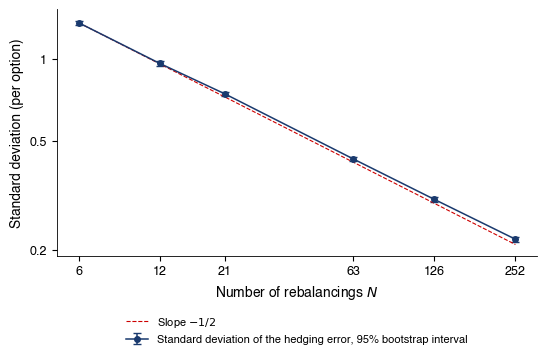

{'prem': 4.485236409022086,
 'sd': {6: 1.3561114441807223,
  12: 0.9630296813486001,
  21: 0.7441251928683007,
  63: 0.4301379906209573,
  126: 0.3059805862658455,
  252: 0.21876310249452238},
 'ci': {6: (1.3312248262461828, 1.3814845678931342),
  12: (0.9453436758236601, 0.9828037011914749),
  21: (0.7307205864922295, 0.7582203370962783),
  63: (0.4216674626228608, 0.4380982311607113),
  126: (0.3003316101381488, 0.3115477077930295),
  252: (0.2145679028364728, 0.22296632255053228)},
 'slope': -0.4886660065637433,
 'slope_lo': -0.49578489854734725,
 'slope_hi': -0.48233299994935763,
 'ratio_63_252': 1.966227328631562}

In [10]:
# Rezolvare
def b1_hedge_boot():
    """Hedging error (standard deviation) for N rebalancings, with a 95% bootstrap interval; log-log slope."""
    rng = np.random.default_rng(SEED)
    S0, K, T, r, s, mu = 100.0, 100.0, 0.25, 0.04, 0.20, 0.08
    paths = gbm_paths(S0, mu, s, T, 252, 10000, seed=SEED)
    prem = float(bs_price(S0, K, T, r, s))
    Ns = [6, 12, 21, 63, 126, 252]
    E = {n: delta_hedge(paths, K, T, r, s, n) for n in Ns}
    idx = rng.integers(0, paths.shape[0], size=(B_BOOT, paths.shape[0]))
    sd = {n: float(E[n].std()) for n in Ns}
    boot = {n: np.array([E[n][i].std() for i in idx]) for n in Ns}
    ci = {n: (float(np.quantile(boot[n], 0.025)), float(np.quantile(boot[n], 0.975))) for n in Ns}
    x = np.log(Ns)
    slope = float(np.polyfit(x, np.log([sd[n] for n in Ns]), 1)[0])
    bs_slopes = np.array([np.polyfit(x, np.log([boot[n][b] for n in Ns]), 1)[0] for b in range(B_BOOT)])
    fig, ax = plt.subplots(figsize=(6.2, 3.2))
    y = np.array([sd[n] for n in Ns]); lo = np.array([ci[n][0] for n in Ns]); hi = np.array([ci[n][1] for n in Ns])
    ax.errorbar(Ns, y, yerr=[y - lo, hi - y], fmt='o-', color=MainBlue, ms=4, capsize=3,
                label='Standard deviation of the hedging error, 95% bootstrap interval')
    ax.plot(Ns, y[0] * np.sqrt(Ns[0] / np.array(Ns)), color=IDAred, lw=0.8, ls='--', label='Slope $-1/2$')
    ax.set_xscale('log'); ax.set_yscale('log')
    from matplotlib.ticker import FixedLocator, FixedFormatter, NullLocator
    ax.xaxis.set_major_locator(FixedLocator(Ns)); ax.xaxis.set_major_formatter(FixedFormatter([str(n) for n in Ns]))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.yaxis.set_major_locator(FixedLocator([0.2, 0.5, 1])); ax.yaxis.set_major_formatter(FixedFormatter(['0.2', '0.5', '1']))
    ax.yaxis.set_minor_locator(NullLocator())
    ax.set_xlabel('Number of rebalancings $N$'); ax.set_ylabel('Standard deviation (per option)')
    legend_outside_bottom(ax, ncol=1, y=-0.2)
    save_fig('ch12_sem_hedge')
    return dict(prem=prem, sd=sd, ci=ci, slope=slope, slope_lo=float(np.quantile(bs_slopes, 0.025)),
                slope_hi=float(np.quantile(bs_slopes, 0.975)), ratio_63_252=sd[63] / sd[252])


b1_hedge_boot()

### B2. Prima de risc a varianței pentru S&P 500 [Rezolvat]

RV înseamnă Realised Variance (varianță realizată), iar VRP înseamnă Variance Risk Premium. Indicii lui RV precizează intervalul randamentelor folosite.

- **Întrebările**

  - este prima de risc a varianței pentru S&P 500 semnificativ pozitivă?

  - a fost aceeași înainte și după 2008?

- **Date**

  - Închideri zilnice S&P 500 și VIX aliniate pe zilele comune, ianuarie 1990 – august 2026 (ultima fereastră de 21 de zile se termină în septembrie 2026)

  - $RV_{t, t + 21}$ ([Notațiile (2/2)](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=sem12n2), $A = 252$, $h = 21$) și $VRP_t$ în %$^2$ și în puncte de volatilitate, ca în [„Prima de risc a varianței”](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=sem12p14)

- **Cerințe**

  1.  Construiți $RV_{t, t + 21}$ din următoarele 21 de randamente logaritmice și $VRP_t$. Păstrați eșantionul comun cu ferestre complete de 21 de randamente viitoare și trecute, inclusiv $RV_{t-21,t}$ folosit la compararea prognozelor.

  2.  Calculați media Variance Risk Premium (VRP), eroarea ei standard Newey–West cu 21 de lag-uri [Newey & West (1987)](https://doi.org/10.2307/1913610), un interval de 95% și eroarea standard naivă $s/\sqrt{n}$.

  3.  Repetați pasul 2 în puncte de volatilitate și calculați ponderea zilelor cu primă pozitivă.

  4.  Repetați pentru 1990–2007 și 2008–2026, apoi testați egalitatea regresînd $VRP_t$ pe o constantă și o variabilă indicator pentru 2008–2026, cu erori Newey–West (21 de lag-uri).

- **Raportați**: un tabel pe perioade și graficul; cîte o propoziție

  - de ce este greșită aici eroarea standard naivă?

  - cît de mare este eroarea?

  - este prima stabilă?

  - de ce este prima în varianță mai puțin precisă decît cea în puncte de volatilitate?

- Notebook: secțiunea [B2](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-B2)

[Exercițiul B2 din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-B2)

<div class="center">

|  | $n$ | VRP mediu (%$^2$) | Interval de încredere 95% | Puncte de volatilitate (eroare standard) | Pozitiv |
|:---|---:|---:|---:|---:|---:|
| 1990–2026 | 9 203 | $113{,}1$ | $[72{,}7, 153{,}6]$ | $4{,}09$ ($0{,}27$) | $86\%$ |
| 1990–2007 | 4 516 | $149{,}3$ | $[125{,}2, 173{,}5]$ | $4{,}60$ ($0{,}25$) | $88\%$ |
| 2008–2026 | 4 687 | $78{,}3$ | $[2{,}7, 153{,}9]$ | $3{,}60$ ($0{,}46$) | $84\%$ |

</div>

- Pașii 1–2: se regresează $VRP_t$ pe o constantă, cu erori standard (Standard Error (SE)) consistente la heteroscedasticitate și autocorelare (Heteroskedasticity and Autocorrelation Consistent, HAC) (Bartlett, 21 de lag-uri: suprapunerea); intervalul $=$ media $\pm 1{,}96$ SE; pe eșantionul complet $t = 113{,}1/20{,}6 = 5{,}49$: se respinge $H_0$ la 5%

- E.s. naivă $5{,}3$ față de Newey–West $20{,}6$: de $3{,}9$ ori prea mică, deoarece ferestrele consecutive au în comun 20 din 21 de zile

- Pasul 3: în puncte de volatilitate $4{,}09$ (SE $0{,}27$), pozitivă în $86\%$ din zile; Pasul 4: 1990–2007 $t = 12{,}12$, 2008–2026 $t = 2{,}03$; diferența $-71{,}0$ %$^2$ ($p = 0{,}08$), în puncte de volatilitate $-1{,}01$ ($p = 0{,}06$)

- **Interpretare**: ridicarea la pătrat amplifică ferestrele de criză (2008, 2020), astfel încît prima exprimată în varianță are cozi mai grele și un interval mai larg decît prima exprimată în puncte de volatilitate; prima este pozitivă în ambele subperioade, dar diferența de mărime nu este semnificativă la 5%: datele nu pot stabili dacă aceasta s-a modificat

[Graficul explicat](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#page=32)

b5_vrp este numele istoric al funcției pentru B2. all/p1/p2 desemnează eșantionul complet și subperioadele; mean/se/lo/hi folosesc unități de varianță, mean_vol/se_vol puncte de volatilitate. ratio_se compară incertitudinea robustă cu cea naivă; figura din link reprezintă același eșantion.

In [11]:
# Rezolvare
def b5_vrp():
    """S&P 500 variance risk premium: mean, Newey-West error (21 lags), subperiods."""
    d = vrp_sp500()
    out = {}
    for tag, x in [('all', d), ('p1', d.loc[:'2007-12-31']), ('p2', d.loc['2008-01-01':])]:
        m, se = nw_mean(x['vrp'], 21)
        mv, sev = nw_mean(x['vrp_vol'], 21)
        out[tag] = dict(n=int(len(x)), mean=m, se=se, t=m / se, lo=m - 1.96 * se, hi=m + 1.96 * se, mean_vol=mv, se_vol=sev,
                        share=float((x['vrp'] > 0).mean()), iv=float(x['vix'].mean()), rv=float(np.sqrt(x['rv']).mean()))
    # stability across subperiods: VRP on a constant and a 2008-2026 dummy, Newey-West errors (21 lags)
    X = sm.add_constant(pd.Series((d.index >= '2008-01-01').astype(float), index=d.index, name='post'))
    for col, tag in [('vrp', 'diff'), ('vrp_vol', 'diff_vol')]:
        m = sm.OLS(d[col], X).fit(cov_type='HAC', cov_kwds={'maxlags': 21})
        out[tag] = dict(d=float(m.params['post']), se=float(m.bse['post']), t=float(m.tvalues['post']),
                        p=float(m.pvalues['post']))
    naive = d['vrp'].std() / np.sqrt(len(d))
    out['naive_se'] = float(naive)
    out['ratio_se'] = out['all']['se'] / float(naive)
    return out


b5_vrp()

{'all': {'n': 9203,
  'mean': 113.1422810966194,
  'se': 20.621026303086406,
  't': 5.486743454649737,
  'lo': 72.72506954257005,
  'hi': 153.55949265066874,
  'mean_vol': 4.0914362055217435,
  'se_vol': 0.2666941672924536,
  'share': 0.858307073780289,
  'iv': 19.43508964468108,
  'rv': 15.343653439159336},
 'p1': {'n': 4516,
  'mean': 149.32446003340172,
  'se': 12.319609516855365,
  't': 12.12087605772731,
  'lo': 125.1780253803652,
  'hi': 173.47089468643824,
  'mean_vol': 4.60408609695,
  'se_vol': 0.2543637310212443,
  'share': 0.8810894596988486,
  'iv': 18.954441984056686,
  'rv': 14.350355887106689},
 'p2': {'n': 4687,
  'mean': 78.28016885456499,
  'se': 38.55935115281425,
  't': 2.0301215273134003,
  'lo': 2.7038405950490585,
  'hi': 153.85649711408092,
  'mean_vol': 3.5974897771688537,
  'se_vol': 0.4600916554436002,
  'share': 0.8363558779603157,
  'iv': 19.8982014081502,
  'rv': 16.30071163098135},
 'diff': {'d': -71.04429117884466,
  'se': 40.478686743894556,
  't': -1.7

### C1. Evaluați critic un răspuns AI [Propus]

- Un student îi cere unui asistent AI: „Evaluează un call european cu scadența peste 90 de zile calendaristice, pe o acțiune fără dividende, cu $S = 100$, $K = 105$, volatilitate 20%, rată continuă $r = 4\%$; apoi dă put-ul din paritatea put–call”

- Asistentul răspunde cu acest cod:

<!-- -->

    import numpy as np
    from scipy.stats import norm
    S, K, r, sigma = 100.0, 105.0, 0.04, 20        # sigma = 20%
    T = 90 / 252                                   # 90 days
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    call = S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    put = call + S - K * np.exp(-r * T)            # put-call parity
    print(f"call = {call:.2f}, put = {put:.2f}")

- „Codul urmează exact Black–Scholes; put-ul rezultă din paritate, deci nu mai e nevoie de a doua formulă”

- **Întrebările**

  - ce trei erori conține răspunsul AI?

  - ce verificare o detectează pe fiecare?

- **Date**: codul de mai sus; totul este corect, cu excepția a trei linii

- **Cerințe**

  1.  Înainte de a rula codul, estimați cît ar trebui să coste un call pe 90 de zile cu 5% în afara banilor: 0,2; 2 sau 20.

  2.  Pentru fiecare eroare, precizați ce este greșit, de ce și cum ați detecta-o: o limită de absență a arbitrajului, o verificare a unităților, noțiunile introductive de azi sau o a doua metodă.

  3.  Corectați cele trei linii, rulați codul, raportați $C$ și $P$ și verificați numeric paritatea put–call.

  4.  Consemnați cele trei erori în `AI_ERRORS.md`, cu cîmpurile: ce s-a cerut, ce a răspuns AI-ul, ce era greșit, cum ați identificat eroarea, varianta corectă.

- **Raportați**: codul corectat și rezultatul; o propoziție despre eroarea care dă totuși un preț plauzibil și una care explică de ce „put-ul rezultă din paritate” nu este o verificare a call-ului

- **Model**: [A1](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-A1), [A2](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-A2) (Black–Scholes pas cu pas)

[Exercițiul C1 din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-C1)

In [12]:
# Codul vostru aici


### B3. Eficiența VIX ca prognoză [Propus]

- **Întrebarea**: este $VIX_t^2$ o prognoză nedeplasată și eficientă a varianței realizate în următoarele 21 de zile de tranzacționare?

- **Date**

  - Seriile zilnice din [B2](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-B2): $RV_{t, t + 21}$ și $VIX_t^2$, 1990–2026; varianța trecută $RV_{t - 21, t}$

  - Pentru pasul 4: HAR-RV (Heterogeneous Autoregressive model for Realised Variance) în logaritmi, prognoza lui în nivel și pierderea Quasi-Likelihood (QLIKE) din secțiunea [„Compararea prognozelor de varianță: HAR-RV, QLIKE, Diebold–Mariano”](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=sem12p17) (fiecare medie cu pragul minim 0,01 %$^2$)

- **Model**: [B2](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-B2) (inferența Newey–West)

- Notebook: secțiunea [B3](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-B3)

- **Cerințe**

  1.  Estimați $RV_{t, t + 21} = \alpha + \beta\,VIX_t^2 + \varepsilon_t$ [Mincer & Zarnowitz (1969)](https://www.nber.org/books-and-chapters/economic-forecasts-and-expectations-analysis-forecasting-behavior-and-performance/evaluation-economic-forecasts) cu erori Newey–West (21 de lag-uri); testați $\alpha = 0$ și $\beta = 1$ separat și împreună (Wald, 5%) și raportați $\mathrm{corr}(\hat\alpha, \hat\beta)$.

  2.  Adăugați $RV_{t - 21, t}$ ca al doilea regresor; apoi reestimați în logaritmi, $\ln RV$ pe $\ln VIX^2$, și testați $\beta = 1$.

  3.  Instrumentați $\ln VIX_t^2$ cu $\ln VIX_{t - 21}^2$ [Christensen & Prabhala (1998)](https://doi.org/10.1016/S0304-405X(98)00034-8) (Generalized Method of Moments (GMM, metoda generalizată a momentelor) exact identificat, covarianță HAC); raportați $t$ din prima etapă și testați $\beta = 1$.

  4.  Din 2000, reestimați la fiecare 21 de zile pe o fereastră extinsă de ținte observate; comparați VIX$^2$ cu HAR-RV prin pierderea QLIKE și testul Diebold–Mariano cu HAC (21 de lag-uri) [Diebold & Mariano (1995)](https://doi.org/10.1080/07350015.1995.10524599), [Patton (2011)](https://doi.org/10.1016/j.jeconom.2010.03.034).

- **Raportați**: toate estimările și testele, cu decizii la 5%; cîte o propoziție

  - de ce pot fi mici ambele statistici $t$, iar testul comun să respingă?

  - ce condiție trebuie să îndeplinească instrumentul?

  - se menține semnificația din eșantion și în afara lui?

[Exercițiul B3 din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-B3)

Reper de replicare: cursul public prezintă deja această analiză. Folosiți exemplul din curs (slide-ul [Calitatea VIX ca prognoză](https://danpele.github.io/MFM/RO/Cursuri/capitol12_optiuni_suprafata_volatilitate.pdf#nameddest=ch12vixforecast)) pentru a verifica implementarea proprie; copierea rezultatului nu rezolvă exercițiul. Raportați alinierea datelor, unitățile și convențiile inferenței.

In [13]:
# Codul vostru aici


### B4. Un zîmbet SVI pentru Bitcoin [Rezolvat]

- **Întrebările**

  - descrie o curbă SVI cu cinci parametri zîmbetul Bitcoin?

  - cît de precis sînt estimate nivelul la bani și asimetria?

- **Date**

  - Secțiunea transversală a opțiunilor din curs; scadența cea mai apropiată de 30 de zile: 2026-10-30, $38$ zile, 56 de opțiuni out of the money (OTM) cotate (put-uri sub forward, call-uri peste); pentru fiecare cotație $k = \ln(K/F)$ și $w = \sigma_{ref}^2\tau$, cu $\sigma_{ref}$ volatilitatea implicită de referință

  - Păstrați cotațiile cu bid și mark Implied Volatility (IV) pozitive, cel puțin două zile pînă la scadență și $|k|<1{,}2$; o scadență estimată are cel puțin șapte cotații. Convertiți mark IV din procente în zecimale înainte de calculul lui $w$.

  - curba SVI $w(k)$ din secțiunea [„Zîmbetul și curba SVI”](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=sem12p11) [Gatheral & Jacquier (2014)](https://doi.org/10.1080/14697688.2013.819986); funcția butterfly $g(k)$ din secțiunea [„Estimarea unui zîmbet și densitatea care rezultă”](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=sem12p12): $g \ge 0$ pentru orice $k$ înseamnă o densitate nenegativă

- **Cerințe**

  1.  Estimați cei cinci parametri SVI prin cele mai mici pătrate pe $w$, cu $b \ge 0$, $|\rho| < 1$, $s > 0$, și raportați rădăcina erorii medii pătratice în puncte de volatilitate.

  2.  Reeșantionați cotațiile cu întoarcere de 300 de ori, reestimați SVI de fiecare dată și raportați intervale de 95% pentru volatilitatea ATM și asimetria $IV(0{,}15) - IV(-0{,}15)$.

  3.  Evaluați $g(k)$ pe $k \in [-1{,}5; 1{,}5]$ și raportați minimul.

- **Raportați**: parametrii, intervalele, $\min g$ și graficul cu cotații, estimare și bandă; cîte o propoziție: ce parametru controlează asimetria și ce semn are; este asimetria semnificativ diferită de 0; de ce estimăm $w$ și nu prețurile

- Notebook: secțiunea [B4](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-B4)

[Exercițiul B4 din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-B4)

- Pasul 1: $\hat a = -0{,}0204$, $\hat b = 0{,}1016$, $\hat\rho = -0{,}2615$, $\hat m = -0{,}0787$, $\hat s = 0{,}3482$; rădăcina erorii medii pătratice $0{,}42$ puncte de volatilitate

- Pasul 2: volatilitatea ATM $36{,}37\%$, Interval de încredere 95% $[36{,}10, 36{,}87]$; skew $-2{,}11$, Interval de încredere 95% $[-2{,}73, -1{,}52]$

- Pasul 3: $\min_k g(k) = 0{,}1359 > 0$ pe $k \in [-1{,}5, 1{,}5]$: nu există arbitraj de tip butterfly pe această grilă

- $\rho$ controlează înclinarea: $\hat\rho < 0$ face aripa put mai scumpă; intervalul pentru skew exclude 0, deci înclinarea este semnificativă la 5%

- De ce $w$: este comparabilă între strike-uri și aproape liniară în aripi, în timp ce prețurile opțiunilor se întind pe patru ordine de mărime și ar pondera ajustarea către opțiunile cele mai scumpe

- O densitate pozitivă peste tot necesită, de asemenea, $g \ge 0$ în afara grilei și condițiile pe aripi din [Gatheral & Jacquier (2014)](https://doi.org/10.1080/14697688.2013.819986)

- **Interpretare**: bootstrap-ul reeșantionează volatilități mark netezite, deci intervalele măsoară zgomotul de ajustare, nu incertitudinea bid–ask: ele sînt o limită inferioară a incertitudinii reale

b3_svi este numele istoric al funcției pentru B4. Citiți nivelul ATM și skew-ul împreună cu intervalele bootstrap; verificarea no-butterfly pe grilă este condiționată de familia SVI estimată.

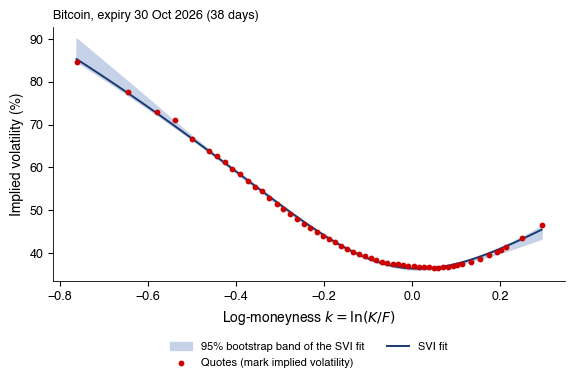

{'expiry': '2026-10-30',
 'days': 38.00625,
 'n': 56,
 'a': -0.020118416761540726,
 'b': 0.10131916183320558,
 'rho': -0.26334811344844206,
 'm': -0.07918714458390937,
 's': 0.3464220267808273,
 'rmse': 0.42441811015902614,
 'atm': 36.36941906636789,
 'rr': -2.0907794271522278,
 'atm_lo': 36.15908191132711,
 'atm_hi': 36.71543758134498,
 'rr_lo': -2.6250998686567986,
 'rr_hi': -1.6869897095541904,
 'gmin': 0.13615811585524487,
 'snapshot': '2026-09-22 07:51:00'}

In [14]:
# Rezolvare
def b3_svi():
    """SVI on the BTC expiry closest to 30 days; pairs bootstrap for the ATM volatility and the skew."""
    c, tab, t0 = btc_surface()
    e = pick(tab, 30)
    g = c[c['expiry'] == e]
    f = tab.loc[e]
    T = float(f['T'])
    k, w = g['k'].values, g['w'].values
    rng = np.random.default_rng(SEED)
    atm, rr, curves = [], [], []
    kk = np.linspace(k.min(), k.max(), 120)
    for _ in range(300):
        i = rng.integers(0, len(k), len(k))
        if len(np.unique(k[i])) < 6:
            continue
        p = svi_fit(k[i], w[i])
        iv = lambda x: 100 * np.sqrt(np.clip(svi_w(x, p['a'], p['b'], p['rho'], p['m'], p['s']), 1e-8, None) / T)
        atm.append(float(iv(0.0))); rr.append(float(iv(0.15) - iv(-0.15))); curves.append(iv(kk))
    curves = np.array(curves)
    # no-butterfly-arbitrage condition (Gatheral-Jacquier): g(k) >= 0
    a, b, rho, m, s = (float(f[x]) for x in ['a', 'b', 'rho', 'm', 's'])
    kg = np.linspace(-1.5, 1.5, 3001)
    W = svi_w(kg, a, b, rho, m, s)
    W1 = b * (rho + (kg - m) / np.sqrt((kg - m) ** 2 + s ** 2))
    W2 = b * s ** 2 / ((kg - m) ** 2 + s ** 2) ** 1.5
    gk = (1 - kg * W1 / (2 * W)) ** 2 - W1 ** 2 / 4 * (1 / W + 0.25) + W2 / 2
    fig, ax = plt.subplots(figsize=(6.6, 3.3))
    ax.fill_between(kk, np.quantile(curves, 0.025, axis=0), np.quantile(curves, 0.975, axis=0), color=LightGray,
                    label='95% bootstrap band of the SVI fit')
    ax.scatter(k, g['mark_iv'], s=10, color=IDAred, label='Quotes (mark implied volatility)', zorder=3)
    ax.plot(kk, 100 * np.sqrt(svi_w(kk, a, b, rho, m, s) / T), color=MainBlue, lw=1.4, label='SVI fit')
    ax.set_xlabel('Log-moneyness $k = \\ln(K/F)$'); ax.set_ylabel('Implied volatility (%)')
    ax.set_title(f"Bitcoin, expiry {pd.Timestamp(e).strftime('%d %b %Y')} ({f['days']:.0f} days)", fontsize=9, loc='left')
    legend_outside_bottom(ax, ncol=2, y=-0.2)
    save_fig('ch12_sem_svi')
    return dict(expiry=str(pd.Timestamp(e).date()), days=float(f['days']), n=int(len(k)), a=a, b=b, rho=rho, m=m, s=s,
                rmse=float(f['rmse_iv']), atm=float(f['atm']), rr=float(f['rr']),
                atm_lo=float(np.quantile(atm, 0.025)), atm_hi=float(np.quantile(atm, 0.975)),
                rr_lo=float(np.quantile(rr, 0.025)), rr_hi=float(np.quantile(rr, 0.975)), gmin=float(gk.min()),
                snapshot=str(t0))


b3_svi()

## Extensii: convexitate, hedging și limite deduse din opțiuni

### A3. Limite și convexitate în prețul de exercitare [Rezolvat]

- **Întrebările**

  - ce restricții fără model trebuie să respecte prețurile call între prețurile de exercitare?

  - le respectă cotațiile Bitcoin?

- **Date**

  - Call-uri europene pe un activ fără dividende, prețul $C(K)$, scadența $\tau$, rata $r$; fără arbitraj, fără fricțiuni

  - Call-uri Bitcoin cu scadența 30 octombrie 2026 din secțiunea transversală a opțiunilor; prețul în USD = prima în BTC $\times$ indicele $S = $ 85 265; forward-ul $F = $ 85 742, deci $e^{r\tau} = F/S$; **mark** = prețul de referință al bursei, **bid**/**ask** = cele mai bune cotații de cumpărare și de vînzare

- **Cerințe**

  1.  Demonstrați $\max(S - Ke^{-r\tau}, 0) \le C \le S$ comparînd plățile a două portofolii în orice stare la $T$.

  2.  Pentru $K_1 < K_2 < K_3$ cu $K_2 = \lambda K_1 + (1 - \lambda)K_3$, demonstrați $\lambda C(K_1) + (1 - \lambda)C(K_3) \ge C(K_2)$.

  3.  Arătați că raportul butterfly $[C(K - h) - 2C(K) + C(K + h)]/h^2$ tinde la $e^{-r\tau}q(K)$, cu $q$ densitatea neutră la risc [Breeden & Litzenberger (1978)](https://doi.org/10.1086/296025).

  4.  Calculați butterfly-ul 84/85/86 de mii din prețurile de referință, $q(85\,000)$ și $P^Q(84\,000 < S_T < 86\,000)$; apoi numărați butterfly-urile negative din toate cele 732 de triplete echidistante, la prețurile de referință și la prețurile executabile (aripile la ask, corpul la bid).

- **Raportați**: demonstrațiile, butterfly-ul, $q(85\,000)$ și numărul de încălcări; este vreo încălcare un arbitraj tranzacționabil?

- Notebook: secțiunea [A3](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-A3)

[Exercițiul A3 din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-A3)

- Pasul 1: un call plus $K e^{-r\tau}$ în numerar valorează $\max(S_T, K) \ge S_T$ la $T$, deci $C + K e^{-r\tau} \ge S$; call-ul plătește $(S_T - K)^+ \ge 0$, deci $C \ge 0$

  - Limita superioară: acțiunea plătește $S_T \ge (S_T - K)^+$ în fiecare stare, deci $C \le S$

- Pasul 2: pentru $S_T$ fixat, aplicația $K \mapsto (S_T - K)^+$ este convexă, deci $\lambda(S_T - K_1)^+ + (1 - \lambda)(S_T - K_3)^+ \ge (S_T - K_2)^+$ în fiecare stare

  - Un portofoliu care plătește cel puțin la fel de mult în fiecare stare costă astăzi cel puțin la fel de mult

- Pasul 3: $C(K) = e^{-r\tau}\int_K^\infty (x - K)q(x)\,dx$, deci $\partial_K C = -e^{-r\tau}\int_K^\infty q(x)\,dx$ și $\partial_K^2 C = e^{-r\tau}q(K)$

  - Raportul butterfly este diferența centrală de ordinul doi, deci converge la $e^{-r\tau}q(K)$: convexitatea înseamnă exact $q \ge 0$

- Pasul 4: $C(84\,000) = 4\,957{,}26$, $C(85\,000) = 4\,414{,}38$, $C(86\,000) = 3\,922{,}98$ USD; butterfly $= 51{,}47$ USD $> 0$

- $q(85\,000) \approx 1{,}0056 \cdot 51{,}47/1\,000^2 = 5{,}18 \cdot 10^{-5}$ per USD; $P^Q(84\,000 < S_T < 86\,000) \approx 2h\,q(K) = 10{,}4\%$

- 7 din 732 de butterfly-uri pe prețuri mark sînt negative (cel mai rău $-11{,}80$ USD, adînc in-the-money, spread median $255{,}80$ USD); la prețuri executabile: 0

- **Interpretare**: nu există arbitraj tranzacționabil, dar o densitate extrasă din prețuri mark brute este negativă în unele zone (barele roșii, 5 din 54 de triplete adiacente): neteziți smile-ul înainte de a deriva

[Graficul explicat](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#page=49)

a1_butterfly este numele istoric al funcției pentru A3. growth = F/S este factorul de capitalizare pînă la scadență; bf_mark și bf_exec sînt costurile butterfly la mark și la prețuri executabile; q este aproximația locală a densității. spread_neg este mediana bid–ask spread-ului la strike-ul central pentru butterfly-urile negative la mark. mass este o masă auxiliară ponderată triunghiular, nu probabilitatea totală a distribuției. n_triples numără toate tripletele echidistante; graficul din link folosește strike-uri adiacente, deci are alt numitor.

In [15]:
# Rezolvare
def a1_butterfly(h=1000.0, K0=85000.0):
    """Convexity in K on the Bitcoin chain: butterfly C(K-h) - 2C(K) + C(K+h) from mark prices in USD (premium in BTC
    x index S, Deribit convention) and the executable cost (wings at the ask, body at the bid); density
    q(K) ~ e^{r tau} butterfly / h^2, with e^{r tau} = F/S (rate implied by the Deribit forward)."""
    c = deribit_chain()
    g = c[(c['expiry'] == pd.Timestamp(BFLY_EXPIRY)) & (c['type'] == 'call')].set_index('strike').sort_index()
    F, S = float(g['forward'].iloc[0]), float(g['index'].iloc[0])
    usd = lambda col: g[col] * S
    m, b, a = usd('mark_price'), usd('bid'), usd('ask')
    out = dict(F=F, S=S, growth=F / S, h=h, K=K0, Cm=float(m[K0 - h]), C0=float(m[K0]), Cp=float(m[K0 + h]),
               bid0=float(b[K0]), askm=float(a[K0 - h]), askp=float(a[K0 + h]))
    out['bf_mark'] = out['Cm'] - 2 * out['C0'] + out['Cp']
    out['bf_exec'] = out['askm'] - 2 * out['bid0'] + out['askp']
    out['q'] = F / S * out['bf_mark'] / h ** 2
    out['mass'] = F / S * out['bf_mark'] / h                 # E^Q[(h - |S_T - K|)^+]/h: triangle-weighted mass ~ h q(K)
    out['p_int'] = 2 * h * out['q']                           # ~ P(K - h < S_T < K + h), unweighted
    # all equally spaced strike triplets in the chain of this expiry
    Ks = list(g.index)
    n_tr = n_neg_mark = n_neg_exec = 0
    neg, spr = [], []
    for i in range(1, len(Ks) - 1):
        for j in range(i + 1, len(Ks)):
            hh = Ks[j] - Ks[i]
            if Ks[i] - hh in g.index:
                n_tr += 1
                bm = m[Ks[i] - hh] - 2 * m[Ks[i]] + m[Ks[j]]
                n_neg_mark += int(bm < 0)
                if bm < 0:
                    neg.append(float(bm)); spr.append(float(a[Ks[i]] - b[Ks[i]]))
                if np.isfinite(a[Ks[i] - hh]) and np.isfinite(b[Ks[i]]) and np.isfinite(a[Ks[j]]) and b[Ks[i]] > 0:
                    n_neg_exec += int(a[Ks[i] - hh] - 2 * b[Ks[i]] + a[Ks[j]] < 0)
    out.update(n_triples=n_tr, n_neg_mark=n_neg_mark, n_neg_exec=n_neg_exec, worst_neg=float(min(neg)) if neg else 0.0,
               spread_neg=float(np.median(spr)) if spr else 0.0)
    return out


a1_butterfly()

{'F': 85741.86,
 'S': 85265.19,
 'growth': 1.005590440835234,
 'h': 1000.0,
 'K': 85000.0,
 'Cm': 4957.2567556632,
 'C0': 4414.3843754079,
 'Cp': 3922.983179748,
 'bid0': 4391.157285,
 'askm': 5030.64621,
 'askp': 3964.831335,
 'bf_mark': 51.4711845954007,
 'bf_exec': 213.16297499999928,
 'q': 5.1758931207600696e-05,
 'mass': 0.051758931207600695,
 'p_int': 0.10351786241520139,
 'n_triples': 732,
 'n_neg_mark': 7,
 'n_neg_exec': 0,
 'worst_neg': -11.8024075998037,
 'spread_neg': 255.79557000000204}

### A4. Paritatea ca regresie: forward-ul implicit [Propus]

- **Întrebarea**: ce preț forward și ce rată a dobînzii în USD implică prețurile opțiunilor Bitcoin prin paritatea put–call?

- **Date**: scadența din [A3](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-A3); prețuri medii în USD $(bid + ask)/2 \times S$; doar prețurile de exercitare la care atît call-ul, cît și put-ul au bid și ask; $D = e^{-r\tau}$ și $F$ necunoscuți

- **Cerințe**

  1.  Arătați din paritatea put–call că $C(K) - P(K) = DF - DK$ pentru orice preț de exercitare.

  2.  Scrieți regresia Ordinary Least Squares (OLS, metoda celor mai mici pătrate) $C_i - P_i = a + bK_i + e_i$ și deduceți $\hat D$ și $\hat F$ din $(\hat a, \hat b)$.

  3.  Deduceți eroarea standard a lui $\hat F$ prin metoda delta, cu o covarianță robustă la heteroscedasticitate.

  4.  Estimați pe date și comparați $\hat F$ cu forward-ul bursei, în erori standard.

- **Raportați**: $\hat D$, $\hat F$ cu erori standard și numărul de prețuri de exercitare

  - ce rată în USD implică $\hat D$?

  - de ce ar putea $\hat F$ să difere de forward-ul bursei?

- **Model**: [A3](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-A3) (portofolii cu plăți identice)

- Notebook: secțiunea [A4](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-A4)

[Exercițiul A4 din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-A4)

In [16]:
# Codul vostru aici


### A5. Ecuația Black–Scholes și rezultatul hedging-ului [Rezolvat]

- **Întrebarea**: cît cîștigă un dealer care vinde o opțiune la $\sigma_{imp}$ și face delta hedging cînd prețul se mișcă cu $\sigma_{real}$?

- **Date**

  - $dS_t = \mu S_t\,dt + \sigma S_t\,dW_t$, $r$ constant, tranzacționare continuă fără costuri; valoarea opțiunii $V(S, t)$ de două ori derivabilă [Black & Scholes (1973)](https://doi.org/10.1086/260062)

  - Cifre: call-ul din [A1](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-A1), vîndut la $\sigma_{imp} = 25\%$, gamma $\Gamma = 0{,}0222$ (din [A1](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-A1)); 252 de zile de tranzacționare pe an

- **Cerințe**

  1.  Replicați $V$ cu un portofoliu autofinanțat din $\Delta$ acțiuni și numerarul $B$ la $r$; aplicați lema lui Itô, alegeți $\Delta$ astfel încît să dispară termenul în $dW_t$ și deduceți ecuația Black–Scholes din absența arbitrajului.

  2.  Pentru un dealer care vinde la $\sigma_{imp}$ și deține $\Delta = \partial_S V^{imp}$, în timp ce $S$ se mișcă cu $\sigma_{real}$, deduceți rezultatul instantaneu.

  3.  Calculați rata de azi a rezultatului pe zi de tranzacționare dacă $\sigma_{real} = 30\%$, apoi anualizați-o cu $S$ și $\Gamma$ fixate.

- **Raportați**: ecuația, formula rezultatului și cele două cifre

  - cine cîștigă?

  - de ce depinde rezultatul de traiectoria lui $S$?

- Notebook: secțiunea [A5](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-A5)

[Exercițiul A5 din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-A5)

- Pasul 1: Itô: $dV = \left(V_t + \mu S V_S + \tfrac{1}{2}\sigma^2 S^2 V_{SS}\right)dt + \sigma S V_S\,dW_t$; portofoliul autofinanțat $\Pi = \Delta S + B$, pornit de la $\Pi = V$, are $d\Pi = \Delta\,dS + rB\,dt$

- $d(V - \Pi) = \left(V_t + \tfrac{1}{2}\sigma^2 S^2 V_{SS} - rB\right)dt + (V_S - \Delta)(\mu S\,dt + \sigma S\,dW_t)$; cu $\Delta = V_S$ dispar atît riscul, cît și $\mu$

- O poziție fără risc care costă 0 cîștigă 0: $V_t + \tfrac{1}{2}\sigma^2 S^2 V_{SS} + r S V_S - r V = 0$

- Pasul 2: portofoliul $-V + \Delta S + (V - \Delta S)$ în numerar variază cu $-dV + \Delta\,dS + r(V - \Delta S)\,dt$ plus dobînda la P&L; lema lui Itô cu $\sigma_{real}$ și ecuația la $\sigma_{imp}$ dau

- $d\,\text{P\&L} = r\,\text{P\&L}\,dt + \tfrac{1}{2}\Gamma S^2\left(\sigma_{imp}^2 - \sigma_{real}^2\right)dt$

- Pasul 3: $\tfrac{1}{2} \cdot 0{,}02223 \cdot 100^2 \cdot (0{,}25^2 - 0{,}30^2)/252 = \tfrac{1}{2} \cdot 0{,}02223 \cdot 10^4 \cdot (-0{,}0275)/252 = -0{,}0121$ per opțiune și zi de tranzacționare

- Anualizat, cu $S$ și $\Gamma$ menținute constante: $-3{,}06$, aproximativ $39\%$ din prețul call-ului, $7{,}76$: o rată, nu P&L-ul realizat al acestei opțiuni pe șase luni, deoarece $\Gamma S^2$ se modifică de-a lungul traiectoriei

- **Interpretare**: vînzătorul pierde cînd volatilitatea realizată depășește volatilitatea implicită; pierderea se acumulează prin $\Gamma$, fiind cea mai mare lîngă strike și aproape de scadență, astfel încît două traiectorii cu aceeași varianță realizată dau P&L-uri diferite

Celula returnează rata P&L pe zi de tranzacționare; înmulțirea cu 252 dă rata anualizată, păstrînd S și gamma constante.

In [17]:
# Rezolvare


g5 = a5_bs()
0.5 * g5['gamma'] * 100 ** 2 * (0.25 ** 2 - 0.30 ** 2) / 252

-0.012130259194528667

### A6. Arborele binomial converge la Black–Scholes [Propus]

- **Întrebările**

  - cît de repede se apropie prețul Cox–Ross–Rubinstein de prețul Black–Scholes?

  - de ce oscilează eroarea?

- **Date**: arborele CRR cu $N$ pași de lungime $\Delta t = T/N$ [Cox, Ross & Rubinstein (1979)](https://doi.org/10.1016/0304-405X(79)90015-1); call-ul european din curs: $S = K = 100$, $T = 1$, $r = 5\%$, $\sigma = 20\%$

- **Cerințe**

  1.  Arătați că $u = e^{\sigma\sqrt{\Delta t}}$, $d = 1/u$, $q = (e^{r\Delta t} - d)/(u - d)$ reproduc exact media neutră la risc și dispersia pasului logaritmic pînă la $O(\Delta t^2)$.

  2.  Evaluați call-ul cu $N = 50, 51, 100, 101, 200, 201$ și calculați $N(C_N - C_{BS})$ pentru fiecare.

  3.  Faceți media prețurilor pentru $N = 200$ și $N = 201$ și comparați eroarea cu cea pentru $N = 200$.

- **Raportați**: un tabel cu $C_N$ și $N(C_N - C_{BS})$; ordinul erorii, motivul oscilației par/impar și de ce ajută media

- **Model**: [A5](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-A5) (de la arbore la ecuația în timp continuu)

- Notebook: secțiunea [A6](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-A6)

[Exercițiul A6 din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-A6)

In [18]:
# Codul vostru aici


### A7. Un hedge delta-gamma [Propus]

- **Întrebările**

  - cîte opțiuni și acțiuni fac un portofoliu de opțiuni vîndute neutru la delta și gamma?

  - este atunci și neutru la vega?

- **Date**

  - Un dealer a **vîndut** 1 000 de call-uri din [A1](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-A1) ($S = K = 100$, șase luni, $r = 3\%$, $\sigma = 25\%$)

  - Instrumente de hedging: un call cu $K = 110$, aceeași scadență și volatilitate constantă $\sigma=25\%$, preț Black–Scholes $3{,}90$, și acțiunea; senzitivitățile din formulele Black–Scholes, gamma pe unitate de $S$

- **Cerințe**

  1.  Calculați delta și gamma poziției dealerului.

  2.  Găsiți numărul $n_2$ de call-uri cu $K = 110$ care anulează gamma, apoi numărul de acțiuni care anulează delta.

  3.  Calculați vega portofoliului cu hedging și explicați rezultatul; păstrați cantitățile fracționare pînă la tabelul final.

- **Raportați**: un tabel al pozițiilor (instrument, cantitate, delta, gamma, vega); este portofoliul protejat față de o schimbare a volatilității?

- **Model**: [A1](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-A1)

- Notebook: secțiunea [A7](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-A7)

[Exercițiul A7 din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-A7)

In [19]:
# Codul vostru aici


### A8. Prețul swap-ului de varianță și eroarea lui de estimare [Propus]

- **Întrebarea**: cît de mari sînt erorile unei benzi finite de opțiuni folosite pentru evaluarea varianței, într-un caz cu răspuns cunoscut?

- **Date**

  - Formula de replicare din curs: $f(S_T) = f(F) + f'(F)(S_T - F) + \int_0^F f''(K)(K - S_T)^+dK + \int_F^\infty f''(K)(S_T - K)^+dK$ [Bakshi, Kapadia & Madan (2003)](https://doi.org/10.1093/rfs/16.1.0101)

  - Reper log-normal: $F = 100$, $r = 0$, 90 de zile ($T = 90/365$), volatilitate constantă 20%, deci varianța exactă este 0,04; prețuri OTM din Black–Scholes; eroarea de **discretizare** = suma Cboe minus integrala densă pe $[80, 120]$; eroarea de **trunchiere** = integrala densă pe $[80, 120]$ minus 0,04

- **Cerințe**

  1.  Aplicați formula cu $f(S) = -2\ln(S/F)$ și arătați că $K_{var} = \frac{2e^{rT}}{T}\left[\int_0^F \frac{P(K)}{K^2}dK + \int_F^\infty \frac{C(K)}{K^2}dK\right]$ pentru traiectorii continue.

  2.  Calculați suma Cboe cu $\Delta K = 5$ pe $[80, 120]$ [Cboe (2025)](https://cdn.cboe.com/api/global/us_indices/governance/Volatility_Index_Methodology_Cboe_Volatility_Index.pdf), integrala densă pe $[80, 120]$ și integrala densă pe $(0, \infty)$.

  3.  Descompuneți eroarea totală în discretizare și trunchiere.

- **Raportați**: cele trei varianțe și volatilități și cele două erori

  - care eroare domină aici?

  - ce se schimbă pentru o scadență mai lungă?

- **Model**: [A3](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-A3) (portofolii de opțiuni ca prețuri ale formelor de plată)

- Notebook: secțiunea [A8](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-A8)

[Exercițiul A8 din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-A8)

In [20]:
# Codul vostru aici


### B5. Opțiuni S&P 500 cu delta hedging, 1990–2026 [Propus]

- **Întrebările**

  - au cîștigat vînzătorii de call-uri S&P 500 pe o lună, cu delta hedging, o primă semnificativă?

  - cu ce tail risk (risc extrem)?

- **Date**

  - Închideri zilnice S&P 500 și VIX, ianuarie 1990 – septembrie 2026; dobînda și dividendele ignorate

  - Convenția fluxurilor: [fluxurile B5](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=sem12-hedge-cash). Strategia din curs: la fiecare 21 de zile de tranzacționare vindem un call ATM pe o lună evaluat cu VIX și îl acoperim zilnic la aceeași volatilitate; rezultatul în % din indice [Bakshi & Kapadia (2003)](https://doi.org/10.1093/rfs/hhg002)

- **Cerințe**

  1.  Calculați rezultatul lunar mediu și eroarea lui standard Newey–West cu 3 lag-uri și testați $H_0$: media $= 0$ la 5%.

  2.  Construiți un interval bootstrap de 95% pe blocuri suprapuse pentru medie (blocuri de 6 luni, 2 000 de reeșantionări) [Künsch (1989)](https://doi.org/10.1214/aos/1176347265).

  3.  Calculați ponderea lunilor pozitive, asimetria și ponderea din cîștigul total pierdută în cele mai rele cinci luni.

- **Raportați**: media cu ambele intervale și statisticile de coadă; de ce poate fi periculoasă o strategie cu o statistică $t$ mare?

- **Model**: [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-B1) (bootstrap), [B2](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-B2) (Newey–West)

- Notebook: secțiunea [B5](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-B5)

[Exercițiul B5 din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-B5)

In [21]:
# Codul vostru aici


### B6. Un VIX pentru Bitcoin [Propus]

- **Întrebările**

  - ce valoare produce formula Cboe VIX pentru Bitcoin?

  - de ce diferă de volatilitățile la bani și de DVOL?

- **Date**: secțiunea transversală a opțiunilor; cele două scadențe din jurul a 30 de zile (2026-10-09, 2026-10-30); prețul mediu în USD $Q$ = prețul mediu în BTC $\times$ indicele $S$; $F$ și $e^{RT} = F/S$ din forward-ul Deribit

- **Cerințe**

  1.  Selectați banda fiecărei scadențe cu regulile Cboe [Cboe (2025)](https://cdn.cboe.com/api/global/us_indices/governance/Volatility_Index_Methodology_Cboe_Volatility_Index.pdf): $K_0$ primul preț de exercitare egal cu $F$ sau imediat sub $F$; put-uri sub $K_0$, call-uri peste, media celor două la $K_0$; eliminați cotațiile bid zero și opriți fiecare aripă după două cotații bid zero consecutive.

  2.  Calculați fiecare varianță implicită $\sigma^2$ cu formula Cboe din secțiunea [„Evaluarea varianței cu opțiuni: VIX”](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=sem12p13) ($R$ în locul lui $r$).

  3.  Interpolați liniar în timp varianțele totale la 30 de zile și raportați $100\sigma_{30}$.

  4.  Comparați cu volatilitățile ATM ale celor două scadențe și cu DVOL în același moment [Alexander & Imeraj (2020)](https://doi.org/10.3905/jai.2020.1.112).

- **Raportați**: cele două varianțe, ponderea scadenței apropiate și indicele

  - de ce este indicele peste ambele volatilități ATM?

  - ce alegeri ar putea explica diferența față de DVOL?

- **Model**: [A8](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-A8) (formula benzii și erorile ei), [B4](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-B4) (aceleași cotații)

- Notebook: secțiunea [B6](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-B6)

[Exercițiul B6 din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-B6)

Reper de replicare: cursul public prezintă deja această analiză. Folosiți exemplul din curs (slide-ul [Exemplu rezolvat: un VIX pentru Bitcoin](https://danpele.github.io/MFM/RO/Cursuri/capitol12_optiuni_suprafata_volatilitate.pdf#nameddest=ch12btcvix)) pentru a verifica implementarea proprie; copierea rezultatului nu rezolvă exercițiul. Raportați alinierea datelor, unitățile și convențiile inferenței.

In [22]:
# Codul vostru aici


### B7. Prima de risc a varianței pentru Bitcoin [Propus]

- **Întrebările**

  - este prima de risc a varianței pentru Bitcoin semnificativ pozitivă?

  - este ea mai mare decît prima acțiunilor?

- **Date**: DVOL (Deribit), martie 2021 – august 2026, și închideri zilnice Bitcoin (`BTC-USD.CC`); volatilitatea realizată în următoarele 30 de zile calendaristice, $A = 365$

- **Cerințe**

  1.  Calculați prima medie DVOL$_t - \sqrt{RV_{t, t + 30}}$ în puncte de volatilitate și eroarea ei standard Newey–West cu 30 de lag-uri și testați-o la 5%.

  2.  Calculați ponderea zilelor pozitive și raportul dintre volatilitatea implicită medie și cea realizată medie și comparați-le cu S&P 500 din [B2](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-B2).

  3.  Numărați perioadele de 30 de zile fără suprapunere din eșantion.

- **Raportați**: prima, testul, rapoartele și mărimea efectivă a eșantionului

  - în ce unitate este prima Bitcoin mai mare?

  - cîtă informație conțin cinci ani de date?

- **Model**: [B2](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-B2)

- Notebook: secțiunea [B7](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-B7)

[Exercițiul B7 din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-B7)

[Definițiile necesare](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#page=60)

Reper de replicare: cursul public prezintă deja această analiză. Folosiți exemplul din curs (slide-ul [Prima de risc a varianței pentru Bitcoin (1/2)](https://danpele.github.io/MFM/RO/Cursuri/capitol12_optiuni_suprafata_volatilitate.pdf#nameddest=ch12vrpbtc)) pentru a verifica implementarea proprie; copierea rezultatului nu rezolvă exercițiul. Raportați alinierea datelor, unitățile și convențiile inferenței.

In [23]:
# Codul vostru aici


### B8. O densitate neutră la risc cu benzi de încredere [Propus]

- **Întrebările**

  - ce probabilitate suplimentară, față de densitatea log-normală, atribuie piața Bitcoin mișcărilor mari?

  - cît de precisă este estimarea?

- **Date**: secțiunea transversală a opțiunilor; scadența cea mai apropiată de 90 de zile: 2026-12-25, $94$ zile, 58 de cotații OTM; SVI estimat ca în [B4](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-B4); prețuri forward (neactualizate)

- **Cerințe**

  1.  Calculați densitatea $q(K) = \partial^2 C/\partial K^2$ din prețurile call SVI (Black-76 cu $F$) pe o grilă fină de prețuri de exercitare [Breeden & Litzenberger (1978)](https://doi.org/10.1086/296025).

  2.  Calculați $P^Q(S_T < 0{,}8F)$ și $P^Q(S_T > 1{,}2F)$ cu intervale bootstrap pe perechi de 95% (300 de reestimări) și valorile log-normale la volatilitatea ATM, cu media $F$ și varianța log $\sigma_{ATM}^2\tau$.

  3.  În fiecare reestimare, recalculați valoarea log-normală la volatilitatea ATM a acelei reestimări și dați un interval de 95% pentru diferența SVI minus log-normal.

  4.  Raportați unde se termină cotațiile în $K/F$ și ce parte din fiecare probabilitate se bazează pe aripi extrapolate.

- **Raportați**: cele două probabilități cu intervale față de log-normal

  - este diferența semnificativă?

  - ce nu măsoară banda bootstrap?

- **Model**: [B4](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-B4) (estimarea SVI și bootstrap-ul pe perechi)

- Notebook: secțiunea [B8](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-B8)

[Exercițiul B8 din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-B8)

In [24]:
# Codul vostru aici


### C2. Este variance risk premium un semnal tranzacționabil? [Propus]

- **Întrebările**

  - ați vinde varianță pe S&P 500 sau pe Bitcoin în fiecare lună ([Carr & Wu (2009)](https://doi.org/10.1093/rfs/hhn038), [Bollerslev, Tauchen & Zhou (2009)](https://doi.org/10.1093/rfs/hhp008))?

  - cînd v-ați opri?

- **Date**

  - Un swap de varianță sintetic cu valoarea noțională vega 1: rezultatul lunar $= (IV^2 - RV)/(2\,IV)$ puncte de volatilitate

  - S&P 500 cu VIX (1990–2026, VIX3M din 2007); Bitcoin cu DVOL (2021–2026); [calendarul C2](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=sem12-calendar)

- **Cerințe**

  1.  Calculați seria lunară a rezultatelor și raportul Sharpe cu interval bootstrap pe blocuri, asimetria, cea mai rea lună și maximum drawdown-ul.

  2.  Testați o regulă de alegere a momentului: omiteți lunile care încep în backwardation (VIX peste VIX3M); este mai bună?

  3.  Verificați cît de fragil este rezultatul la ziua în care începe grila lunară.

  4.  Comparați cu opțiunea cu delta hedging din [B5](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-B5) și propuneți o mărime a poziției.

- **Raportați**: un tabel și un grafic al rezultatului cumulat; un verdict cu limitările lui

- **Model**: [B2](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-B2), [B7](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-B7); regresiile predictive din anexa cursului

[Exercițiul C2 din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-C2)

In [25]:
# Codul vostru aici


### C3. Testarea limitei Martin [Propus]

- **Întrebarea**: este limita inferioară a primei de risc a acțiunilor din [Martin (2017)](https://doi.org/10.1093/qje/qjw034) validă și strînsă pe datele cursului, ca în studiul de caz [Back, Crotty & Kazempour (2022)](https://doi.org/10.1016/j.jfineco.2022.02.003)?

- **Date**

  - Limita zilnică Martin publicată de autori, în % anualizat, $h = 1, 3, 6, 12$ luni, 1990–2020 (coloanele `lb_m_h` din `market_bounds.csv`, [pachetul de replicare](https://doi.org/10.5281/zenodo.6115448))

  - S&P 500 (`GSPC.INDX`); rata zilnică fără risc ([Kenneth French Data Library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html)); predictorii lunari Welch–Goyal [Welch & Goyal (2008)](https://doi.org/10.1093/rfs/hhm014) ([pagina de date a lui Amit Goyal](https://sites.google.com/view/agoyal145))

- **Cerințe**

  1.  Calculați randamentul zilnic în exces (randamentul prețului minus rata fără risc), compuneți-l pe 21, 63, 126 și 252 de zile de tranzacționare și anualizați cu $12/h$, pentru datele de formare 31 ianuarie 1990 – decembrie 2020 ($N = 7\,789$ la 1 lună, $7\,598$ la 12 luni).

  2.  Construiți cele nouă variabile de condiționare pozitive din Tabelul 3 (valorile de la sfîrșitul fiecărei luni, păstrate pe parcursul lunii următoare) și formați cele 10 momente $s_{t,T}(1, z_t)$ cu $s_{t,T} = R^e_{t,T} - b_{t,T}$ și media lor $\bar\lambda$.

  3.  Estimați $\Sigma$ prin Hansen–Hodrick [Hansen & Hodrick (1980)](https://doi.org/10.1086/260910) cu $21h$ lag-uri (Newey–West cu $1{,}5 \times 21h$ lag-uri dacă nu este pozitiv semidefinită) și calculați $D_1$, $D_2$ și p-value-urile lor [Kodde & Palm (1986)](https://doi.org/10.2307/1912331).

  4.  Regresați $R^e_{t,T}$ pe o constantă și $b_{t,T}$ (erori Hansen–Hodrick) și testați împreună $\alpha = 0$, $\beta = 1$; repetați pasul 3 cu limita înlocuită de media ei în timp (Secțiunea 4.3).

- **Raportați**: un tabel cu mediile, $D_1$, $D_2$ și p-value-urile alături de Tabelele 1 și 3 și o propoziție care explică de ce testul din regresie și testul limitei strînse pot da concluzii diferite

- **Model**: [B2](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-B2) (ferestre suprapuse și erori HAC)

[Exercițiul C3 din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#nameddest=ex-C3)

[Definițiile necesare](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#page=65); [Statisticile de validitate și limită strînsă](https://danpele.github.io/MFM/RO/Seminarii/seminar12_optiuni_suprafata_volatilitate_ro.pdf#page=66)

In [26]:
# Codul vostru aici
